# Link Splendor Scores

We generate plots of the link-level splendor score:
- a map of the main specification (as defined in [src/splendor/config.py](../../src/splendor/config.py))
- close-ups of the highest- and lowest-ranked links
- how sensitive the ranking is to the methodological choices (normalization, component weights, land use measure)

To do this, we read the output from [scripts/links/compute_score.py](../../scripts/links/compute_score.py).

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [15]:
import numpy as np
import pandas as pd

from splendor.config import (
    STUDY_AREA,
    CORRIDOR_RADIUS,
    ROAD_STRIP_RADIUS,
    MAIN_SPECIFICATION,
    COMPONENT_WEIGHTS,
    REFERENCE_WEIGHTS,
    TOP_SHARE
)
from splendor.io import load_network, load_raster, load_rank_correlations
from splendor.landuse.corridors import get_link_corridors
from splendor.composite.sensitivity import COMBINATION_COLUMNS, summarize_correlations
from splendor.paths import (
    network_path,
    basemap05_main_types_path,
    landuse_path,
    score_grid_path,
    rank_summary_path,
    rank_correlations_path,
    splendor_path,
    components_path,
    landuse_plot_path,
    score_map_path,
    ensure_parent
)
from splendor.plotting.scores import plot_link_maps, plot_rank_correlations
from splendor.plotting.charts import plot_distributions, plot_against
from splendor.plotting.landuse import plot_link_landuse_grid

LEVEL = "links"

PATH_ARGS = (STUDY_AREA, LEVEL, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS)
N_CLOSE_UPS = 4 # Links per top/bottom grid

WEIGHT_COLUMNS = ["land_use_weight", "poi_weight", "attractiveness_weight"]
weight_label = lambda weights: "/".join(f"{w:.2g}" for w in weights) # (0.6, 0.2, 0.2) -> "0.6/0.2/0.2"

### 0.2. Data

In [16]:
_, edges = load_network(network_path(STUDY_AREA))
edges = edges.sort_values("edge_id").reset_index(drop=True)

splendor = pd.read_csv(splendor_path(*PATH_ARGS))
grid = pd.read_csv(score_grid_path(*PATH_ARGS))
summary = pd.read_csv(rank_summary_path(*PATH_ARGS))
correlations = load_rank_correlations(rank_correlations_path(*PATH_ARGS), COMBINATION_COLUMNS)
components = pd.read_csv(components_path(*PATH_ARGS))
links = edges[["edge_id", "length_m", "poi_diversity"]].merge(splendor, on="edge_id", validate="one_to_one")

# For the close-ups
raster, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))
shares = pd.read_csv(landuse_path(*PATH_ARGS)).set_index("edge_id")
corridors = get_link_corridors(edges, CORRIDOR_RADIUS)

<br><br>

## 1. Main Specification

Main specification: measure shannon, normalization zscore, aggregation mean, land_use_weight 0.5, poi_weight 0.25, attractiveness_weight 0.25


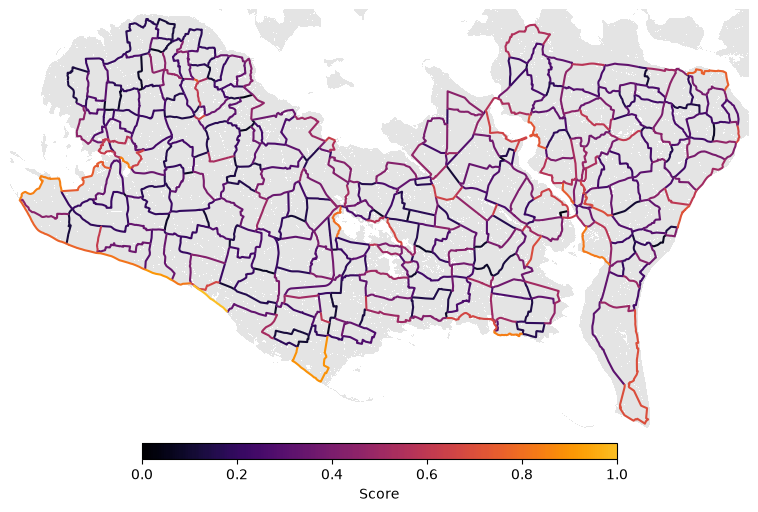

In [17]:
spec = ", ".join(f"{k} {v}" for k, v in MAIN_SPECIFICATION.items())
print("Main specification:", spec)
fig = plot_link_maps(
    edges, splendor, ["score"], [""], ["Score"], # Empty title for the report
    panel_size=(8, 5), background=(raster, transform)
);
fig.savefig(ensure_parent(score_map_path(STUDY_AREA, LEVEL, CORRIDOR_RADIUS)))

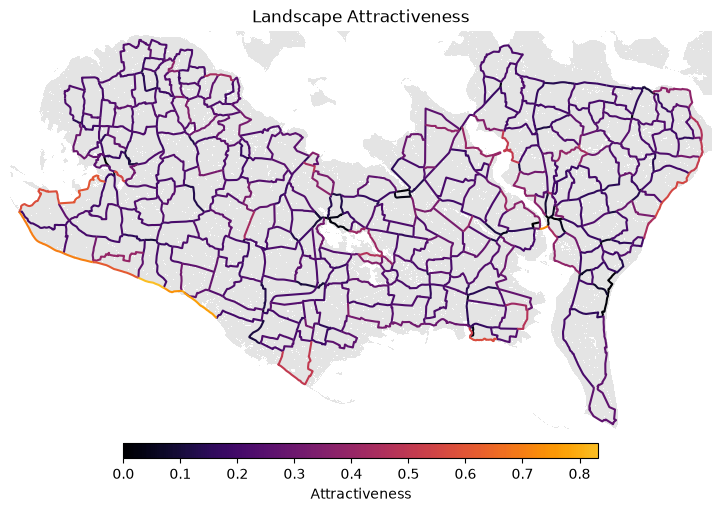

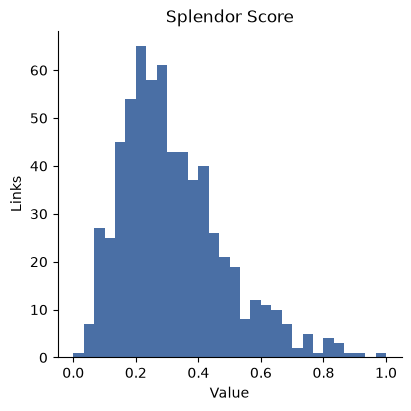

In [18]:
plot_link_maps(
    edges, components, ["attractiveness"], ["Landscape Attractiveness"], ["Attractiveness"], 
    panel_size=(8, 5), background=(raster, transform)
);
plot_distributions(splendor, ["score"], titles=["Splendor Score"]);

<br><br>

## 2. Top and Bottom links

Saved /Users/sanderengelthilo/dev/bikenwsplendor/plots/pilot/link_landuse_top_r100.png
Saved /Users/sanderengelthilo/dev/bikenwsplendor/plots/pilot/link_landuse_bottom_r100.png


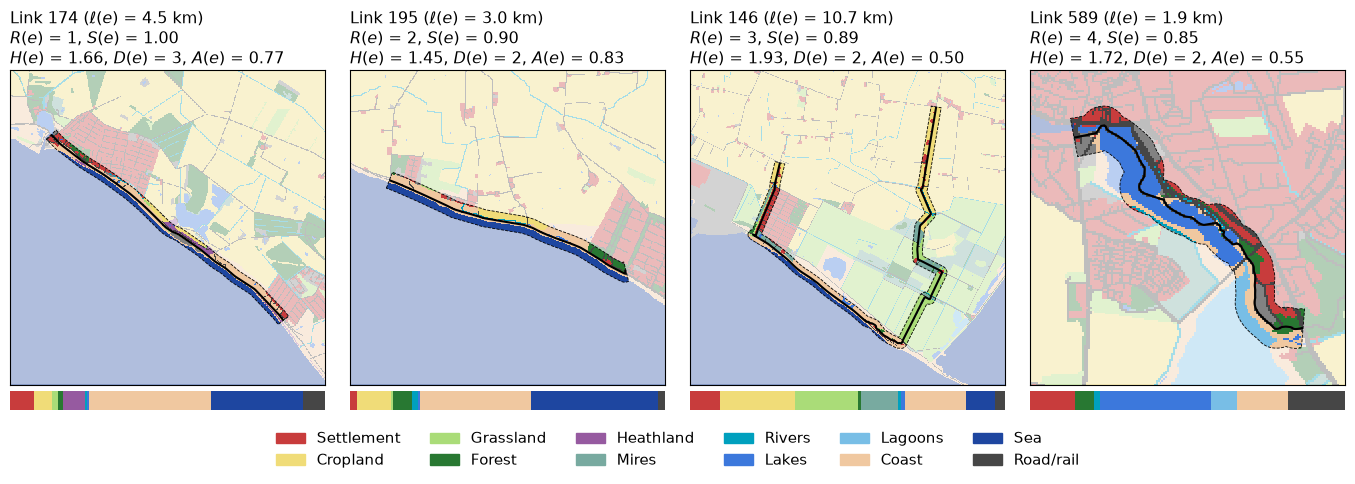

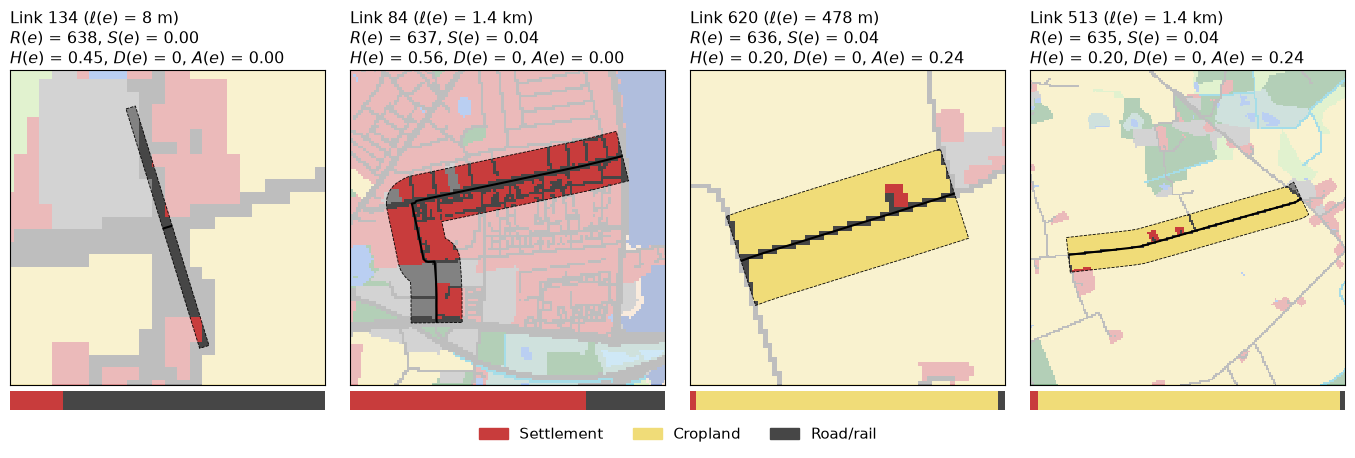

In [19]:
main = splendor.set_index("edge_id")
poi = edges.set_index("edge_id")["poi_diversity"]
attractiveness = components.set_index("edge_id")["attractiveness"]
diversity = components.set_index("edge_id")["diversity_shannon"]
details = (
    main["rank"].map(lambda r: f"$R(e)$ = {int(r):,}")
    + main["score"].map(lambda s: f", $S(e)$ = {s:.2f}")
    + diversity.map(lambda h: f"\n$H(e)$ = {h:.2f}")
    + poi.map(lambda p: f", $D(e)$ = {p}")
    + attractiveness.map(lambda a: f", $A(e)$ = {a:.2f}")
)

top = splendor.nsmallest(N_CLOSE_UPS, "rank")["edge_id"].to_numpy()
bottom = splendor.nlargest(N_CLOSE_UPS, "rank")["edge_id"].to_numpy()

for edge_ids, label in [(top, "Top"), (bottom, "Bottom")]:
    fig = plot_link_landuse_grid(
        edge_ids, edges, corridors, shares, raster, transform,
        details=details, symbol="e", fontsize=11.5, show_pixels=False
        # title=f"{label} {N_CLOSE_UPS} Links by Splendor Score"
    )
    OUT = landuse_plot_path(STUDY_AREA, LEVEL, CORRIDOR_RADIUS, label.lower())
    fig.savefig(ensure_parent(OUT), dpi=150)
    print(f"Saved {OUT}")

<br><br>

## 3. Rank Sensitivity

,edge_id,median_rank,iqr_rank,min_rank,max_rank
174,174,1.000000,9.750000,1.000000,117.000000
63,63,3.000000,3.250000,1.000000,10.000000
188,188,4.000000,8.500000,1.000000,19.000000
254,254,4.500000,4.000000,1.000000,11.000000
577,577,5.000000,5.000000,4.000000,12.000000
589,589,6.000000,3.250000,3.000000,14.000000
18,18,7.000000,16.500000,2.000000,118.000000
146,146,7.000000,1.250000,2.000000,16.000000
350,350,7.000000,5.750000,2.000000,16.000000
195,195,8.000000,9.000000,2.000000,22.000000


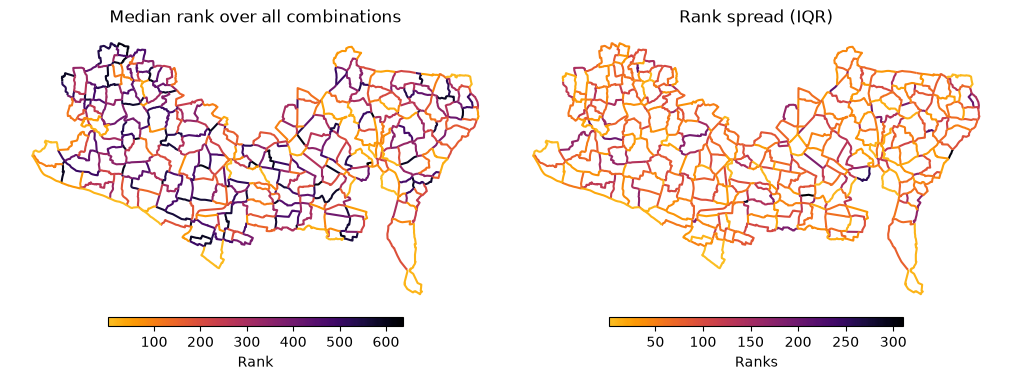

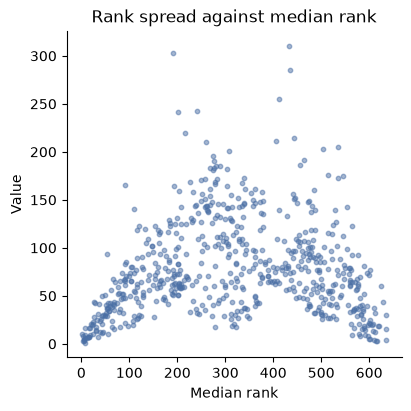

In [20]:
plot_link_maps(
    edges, summary,
    ["median_rank", "iqr_rank"],
    ["Median rank over all combinations", "Rank spread (IQR)"],
    ["Rank", "Ranks"],
    low_is_best=[True, True],
);

plot_against(summary, "median_rank", ["iqr_rank"], titles=["Rank spread against median rank"], xlabel="Median rank");

summary.nsmallest(20, "median_rank")[["edge_id", "median_rank", "iqr_rank", "min_rank", "max_rank"]].style

In [21]:
n = len(summary)
top = summary.nsmallest(int(np.ceil(TOP_SHARE * n)), "median_rank")
print(f"Median rank IQR as share of the {n} links: "
      f"top {TOP_SHARE:.0%} ({len(top)} links) {top['iqr_rank'].median() / n:.1%}, "
      f"all {summary['iqr_rank'].median() / n:.1%}")

Median rank IQR as share of the 638 links: top 5% (32 links) 1.9%, all 10.6%


<br><br>

## 4. Rank Correlations

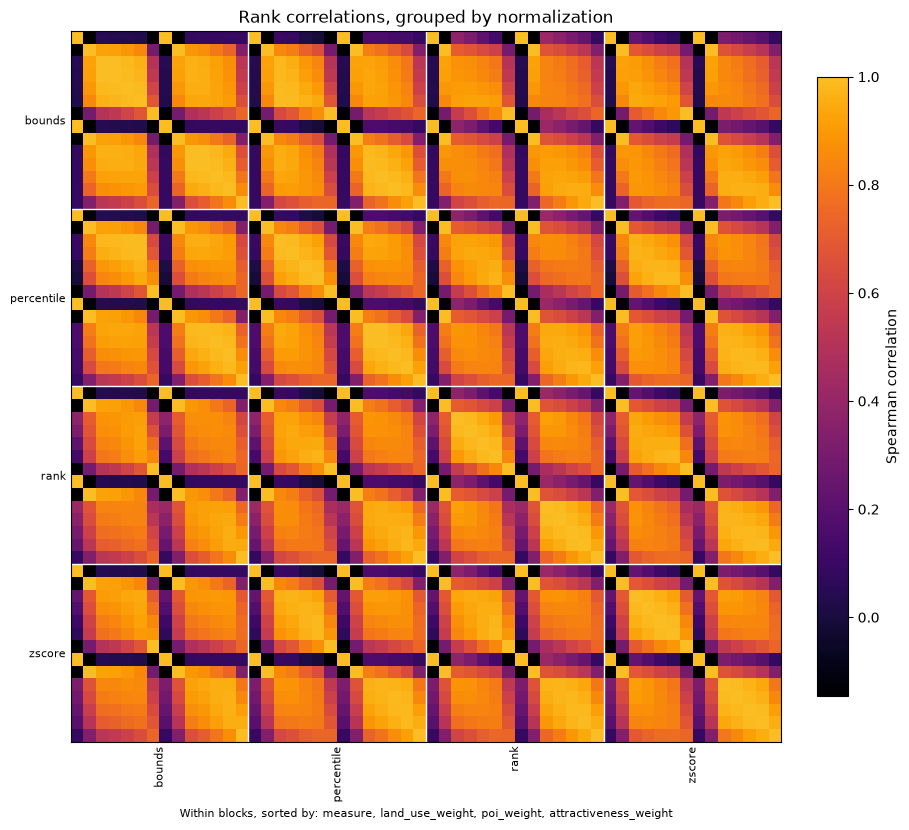

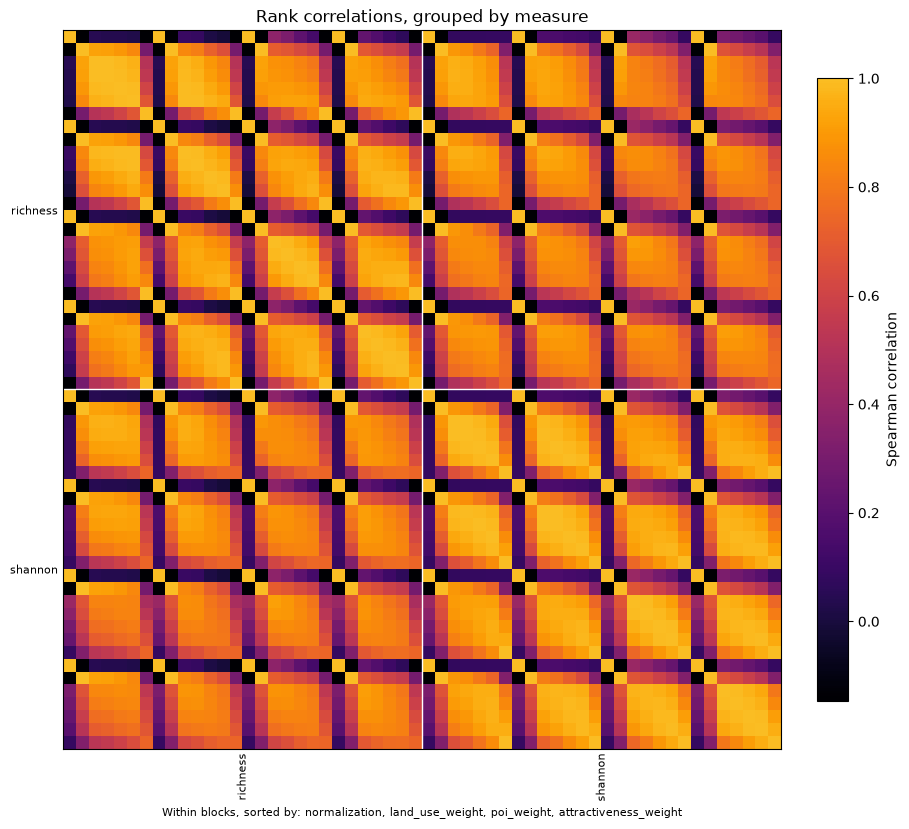

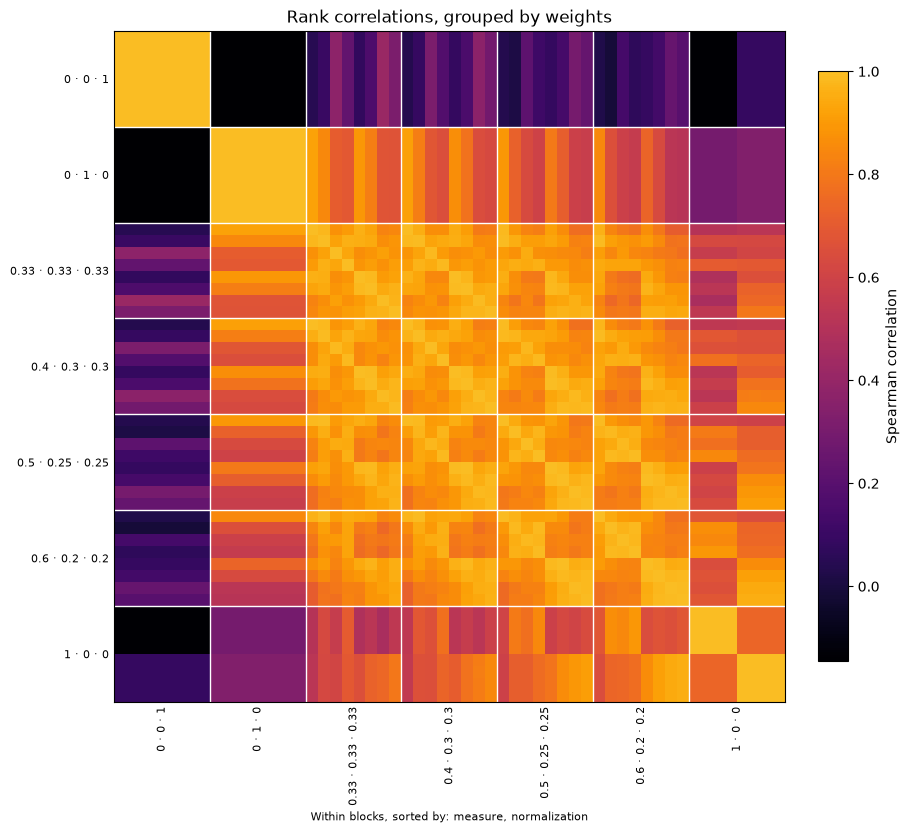

In [22]:
groupings = {
    "normalization": ["normalization"],
    "measure": ["measure"],
    "weights": ["land_use_weight", "poi_weight", "attractiveness_weight"],
}
for name, outer in groupings.items():
    order = outer + [level for level in COMBINATION_COLUMNS if level not in outer]
    plot_rank_correlations(
        correlations, level_order=order, n_label_levels=len(outer),
        title=f"Rank correlations, grouped by {name}",
    )

In [23]:
print(summarize_correlations(correlations, COMPONENT_WEIGHTS).round(3))

                    count    min  median    max
all pairs           496.0  0.708   0.894  0.998
only measure         16.0  0.819   0.895  0.964
only normalization   48.0  0.877   0.954  0.991
only weights         48.0  0.898   0.980  0.998


<br><br>

## 5. Reference Rankings

weights         0.5/0.25/0.25  0.6/0.2/0.2  0.4/0.3/0.3  0.33/0.33/0.33  \
weights                                                                   
0.5/0.25/0.25            1.00         0.99         0.99            0.97   
0.6/0.2/0.2              0.99         1.00         0.97            0.94   
0.4/0.3/0.3              0.99         0.97         1.00            0.99   
0.33/0.33/0.33           0.97         0.94         0.99            1.00   
1/0/0                    0.91         0.95         0.85            0.80   
0/1/0                    0.57         0.51         0.63            0.67   
0/0/1                    0.24         0.20         0.28            0.31   

weights         1/0/0  0/1/0  0/0/1  
weights                              
0.5/0.25/0.25    0.91   0.57   0.24  
0.6/0.2/0.2      0.95   0.51   0.20  
0.4/0.3/0.3      0.85   0.63   0.28  
0.33/0.33/0.33   0.80   0.67   0.31  
1/0/0            1.00   0.33   0.09  
0/1/0            0.33   1.00  -0.15  
0/0/1            0.0

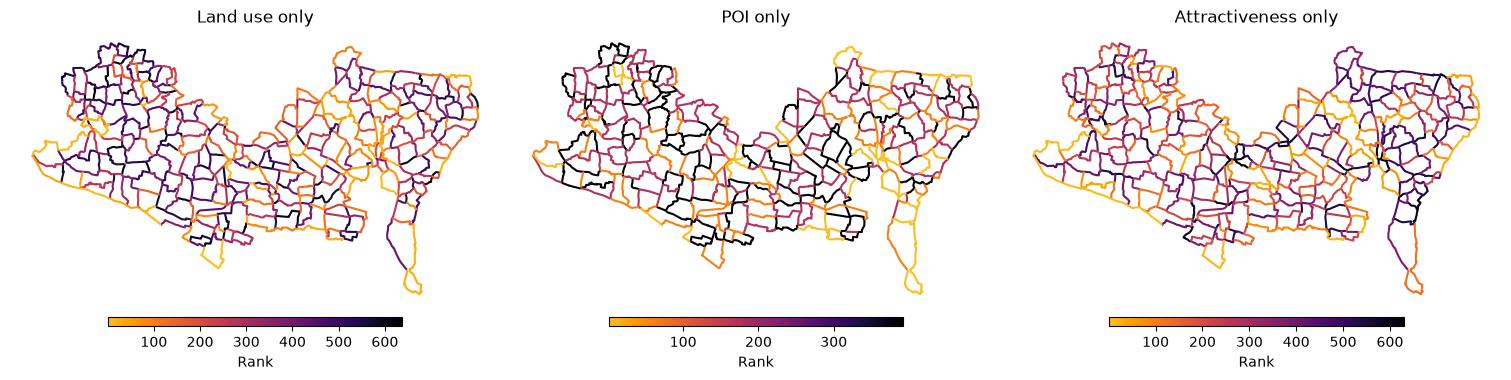

In [24]:
# Same measure, normalization and aggregation as the main specification, all weights
same = grid
for column in ("measure", "normalization", "aggregation"):
    same = same[same[column] == MAIN_SPECIFICATION[column]]

order = [weight_label(w) for w in (*COMPONENT_WEIGHTS, *REFERENCE_WEIGHTS)]
same = same.assign(weights=same[WEIGHT_COLUMNS].apply(weight_label, axis=1))
ranks_by_weight = same.pivot(index="edge_id", columns="weights", values="rank")[order]
print(ranks_by_weight.corr(method="spearman").round(2))

reference_names = {"1/0/0": "land_use_only", "0/1/0": "poi_only", "0/0/1": "attractiveness_only"}
references = ranks_by_weight[list(reference_names)].rename(columns=reference_names).reset_index()
plot_link_maps(
    edges, references,
    list(reference_names.values()),
    ["Land use only", "POI only", "Attractiveness only"],
    ["Rank", "Rank", "Rank"],
    low_is_best=[True, True, True],
);

<br><br>

## 6. Length Dependence

          length_m  score
length_m      1.00   0.23
score         0.23   1.00


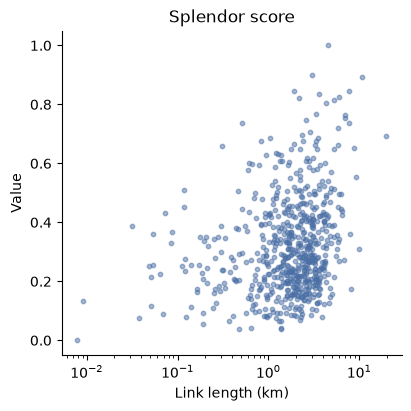

In [25]:
print(links[["length_m", "score"]].corr(method="spearman").round(2))
plot_against(
    links, "length_m", ["score"],
    titles=["Splendor score"], xlabel="Link length (km)",
    x_scale_factor=1 / 1000, xscale="log",
);

<br><br>

## 7. Conclusion

**Top links**

The top 10 are mostly coastal: sea, coast or lagoons are among the three largest land use types on 8 of them, and their attractiveness is mostly between 0.5 and 0.83. They combine this with high land use diversity (Shannon 1.36–1.93). POI no longer decides the top: 9 of the top 20 have all three POI categories, and the rest have fewer, down to none.

**Bottom links**

The lowest-ranked links are near-pure cropland (96–99%) or settlement with roads, without POIs. The very last is the shortest link in the network (8 m, mostly road), where the corridor holds only a few pixels.

**Robustness**

The top links are stable across the methodological choices: their rank spread (IQR) is a median of 1.9% of the ranking for the top 5%, against 10.6% for all links. The four weightings rank links almost identically (Spearman 0.94–0.99), so the exact split of the weights matters little.

**Components**

The main specification correlates 0.91 with diversity alone, 0.57 with POI alone and 0.24 with attractiveness alone, so diversity drives the ranking, as intended. The score depends only weakly on link length (Spearman 0.23).